# API Design Fundamentals: HTTP, REST, OpenAPI

An **API** (application programming interface) is the contract between two programs. Most APIs today are web APIs: a client sends an HTTP request, a server returns an HTTP response with JSON. Good API design makes integrations easy and safe; bad design causes bugs in every client.

**After this lesson you can:**

1. Explain HTTP methods, status codes, headers and idempotency.
2. Design REST resources, pagination, filtering, versioning and error responses.
3. Describe an API with an OpenAPI document.
4. Build and test a small REST API with the standard library and measure its latency.

M30 builds production APIs with FastAPI. This lesson shows the principles underneath, with only the standard library.

## 1. HTTP in One Table

| Method | Meaning | Safe | Idempotent | Typical status codes |
| :--- | :--- | :-: | :-: | :--- |
| `GET` | read a resource | yes | yes | 200, 404 |
| `POST` | create a resource / run an action | no | no | 201, 400, 409 |
| `PUT` | replace a resource | no | yes | 200, 204 |
| `PATCH` | change part of a resource | no | no* | 200 |
| `DELETE` | delete a resource | no | yes | 204, 404 |

- **Safe:** the request does not change data.
- **Idempotent:** sending the request twice has the same effect as sending it once. Clients can retry idempotent requests after a timeout.

Status code families: **2xx** success, **3xx** redirect, **4xx** client error (the request is wrong), **5xx** server error (the server failed).

## 2. REST Resource Design

- Use **nouns** for resources and HTTP methods for actions: `GET /books/42`, not `GET /getBook?id=42`.
- Use **plural** collection names: `/books`, `/books/42/reviews`.
- **Filter, sort and paginate** with query parameters: `/books?author=Orhan%20Pamuk&sort=-year&limit=10&offset=20`.
- **Version** the API: `/v1/books`. Breaking changes go to `/v2`.
- Return errors in one consistent format. **RFC 9457 "Problem Details"** defines one: `{"type", "title", "status", "detail"}`.
- Support **idempotency keys** for `POST` requests that clients may retry (payments!): the server remembers the key and does not create a duplicate.

## 3. Build a Small REST API

The server below implements these rules for a `books` resource: list with pagination and filtering, read one, create with validation and an idempotency key, and Problem Details errors. Pydantic validates the input.

In [1]:
import json
import threading
import time
import urllib.error
import urllib.request
from http.server import BaseHTTPRequestHandler, ThreadingHTTPServer
from urllib.parse import parse_qs, urlparse

from pydantic import BaseModel, Field, ValidationError

class BookIn(BaseModel):
    title: str = Field(min_length=1, max_length=200)
    author: str = Field(min_length=1)
    year: int = Field(ge=1450, le=2100)

BOOKS = {1: {"id": 1, "title": "Kar", "author": "Orhan Pamuk", "year": 2002},
         2: {"id": 2, "title": "Masumiyet Müzesi", "author": "Orhan Pamuk", "year": 2008},
         3: {"id": 3, "title": "Tutunamayanlar", "author": "Oğuz Atay", "year": 1972}}
IDEMPOTENCY: dict[str, int] = {}
LOCK = threading.Lock()

class BooksAPI(BaseHTTPRequestHandler):
    def send_json(self, status: int, body, content_type="application/json"):
        data = json.dumps(body, ensure_ascii=False).encode()
        self.send_response(status)
        self.send_header("Content-Type", content_type)
        self.send_header("Content-Length", str(len(data)))
        self.end_headers()
        self.wfile.write(data)

    def problem(self, status: int, title: str, detail: str):
        self.send_json(status, {"type": "about:blank", "title": title, "status": status, "detail": detail},
                       "application/problem+json")

    def do_GET(self):
        url = urlparse(self.path)
        parts = url.path.strip("/").split("/")
        if parts[:2] == ["v1", "books"] and len(parts) == 2:
            q = parse_qs(url.query)
            items = sorted(BOOKS.values(), key=lambda b: b["id"])
            if "author" in q:
                items = [b for b in items if b["author"] == q["author"][0]]
            limit, offset = int(q.get("limit", [10])[0]), int(q.get("offset", [0])[0])
            return self.send_json(200, {"items": items[offset:offset + limit], "total": len(items),
                                        "limit": limit, "offset": offset})
        if parts[:2] == ["v1", "books"] and len(parts) == 3 and parts[2].isdigit():
            book = BOOKS.get(int(parts[2]))
            return self.send_json(200, book) if book else self.problem(404, "Not Found", f"book {parts[2]} does not exist")
        self.problem(404, "Not Found", f"no route for {url.path}")

    def do_POST(self):
        if self.path != "/v1/books":
            return self.problem(404, "Not Found", "no route")
        try:
            book = BookIn.model_validate_json(self.rfile.read(int(self.headers["Content-Length"])))
        except ValidationError as err:
            return self.problem(422, "Validation Error", "; ".join(f"{e['loc'][0]}: {e['msg']}" for e in err.errors()))
        key = self.headers.get("Idempotency-Key")
        with LOCK:
            if key and key in IDEMPOTENCY:
                return self.send_json(200, BOOKS[IDEMPOTENCY[key]])         # replay: no duplicate
            new_id = max(BOOKS) + 1
            BOOKS[new_id] = {"id": new_id, **book.model_dump()}
            if key:
                IDEMPOTENCY[key] = new_id
        self.send_json(201, BOOKS[new_id])

    def log_message(self, *args):
        pass

server = ThreadingHTTPServer(("127.0.0.1", 0), BooksAPI)
BASE = f"http://127.0.0.1:{server.server_address[1]}"
threading.Thread(target=server.serve_forever, daemon=True).start()
print("API running at", BASE)

API running at http://127.0.0.1:37007


## 4. Call the API

A small client function sends requests and prints the status code and the body.

In [2]:
def call(method: str, path: str, body=None, headers=None):
    data = json.dumps(body).encode() if body is not None else None
    req = urllib.request.Request(BASE + path, data=data, method=method,
                                 headers={"Content-Type": "application/json", **(headers or {})})
    try:
        with urllib.request.urlopen(req) as r:
            status, payload = r.status, json.loads(r.read())
    except urllib.error.HTTPError as err:
        status, payload = err.code, json.loads(err.read())
    print(f"{method:<4} {path:<38} -> {status} {json.dumps(payload, ensure_ascii=False)[:110]}")
    return status, payload

call("GET", "/v1/books?author=Orhan%20Pamuk&limit=1")
call("GET", "/v1/books/3")
call("GET", "/v1/books/99")
call("POST", "/v1/books", {"title": "", "author": "X", "year": 3000})
key = {"Idempotency-Key": "order-7f3a"}
call("POST", "/v1/books", {"title": "İnce Memed", "author": "Yaşar Kemal", "year": 1955}, key)
call("POST", "/v1/books", {"title": "İnce Memed", "author": "Yaşar Kemal", "year": 1955}, key)   # client retry
print("books stored:", len(BOOKS), "(the retry did not create a duplicate)")

GET  /v1/books?author=Orhan%20Pamuk&limit=1 -> 200 {"items": [{"id": 1, "title": "Kar", "author": "Orhan Pamuk", "year": 2002}], "total": 2, "limit": 1, "offset"
GET  /v1/books/3                            -> 200 {"id": 3, "title": "Tutunamayanlar", "author": "Oğuz Atay", "year": 1972}
GET  /v1/books/99                           -> 404 {"type": "about:blank", "title": "Not Found", "status": 404, "detail": "book 99 does not exist"}
POST /v1/books                              -> 422 {"type": "about:blank", "title": "Validation Error", "status": 422, "detail": "title: String should have at le
POST /v1/books                              -> 201 {"id": 4, "title": "İnce Memed", "author": "Yaşar Kemal", "year": 1955}
POST /v1/books                              -> 200 {"id": 4, "title": "İnce Memed", "author": "Yaşar Kemal", "year": 1955}
books stored: 4 (the retry did not create a duplicate)


## 5. Describe the API with OpenAPI

**OpenAPI** is a standard, machine-readable description of an HTTP API. Tools generate documentation pages, client libraries and tests from it. Pydantic produces the JSON Schema of the request body; FastAPI (M30) generates the whole document automatically.

In [3]:
openapi = {
    "openapi": "3.1.0",
    "info": {"title": "Books API", "version": "1.0.0"},
    "paths": {
        "/v1/books": {
            "get": {"summary": "List books", "parameters": [
                {"name": "author", "in": "query", "schema": {"type": "string"}},
                {"name": "limit", "in": "query", "schema": {"type": "integer", "default": 10}},
                {"name": "offset", "in": "query", "schema": {"type": "integer", "default": 0}}],
                "responses": {"200": {"description": "A page of books"}}},
            "post": {"summary": "Create a book",
                     "parameters": [{"name": "Idempotency-Key", "in": "header", "schema": {"type": "string"}}],
                     "requestBody": {"content": {"application/json": {"schema": BookIn.model_json_schema()}}},
                     "responses": {"201": {"description": "Created"}, "422": {"description": "Validation error"}}},
        },
        "/v1/books/{id}": {"get": {"summary": "Get one book", "responses": {"200": {"description": "The book"},
                                                                             "404": {"description": "Not found"}}}},
    },
}
print(json.dumps(openapi["paths"]["/v1/books"]["post"]["requestBody"], indent=2, ensure_ascii=False))

{
  "content": {
    "application/json": {
      "schema": {
        "properties": {
          "title": {
            "maxLength": 200,
            "minLength": 1,
            "title": "Title",
            "type": "string"
          },
          "author": {
            "minLength": 1,
            "title": "Author",
            "type": "string"
          },
          "year": {
            "maximum": 2100,
            "minimum": 1450,
            "title": "Year",
            "type": "integer"
          }
        },
        "required": [
          "title",
          "author",
          "year"
        ],
        "title": "BookIn",
        "type": "object"
      }
    }
  }
}


## 6. Measure Latency

API performance is described with **latency percentiles**: p50 (median), p95 and p99. The mean hides slow outliers, but users feel them. The cell sends 300 `GET` requests and plots the distribution.

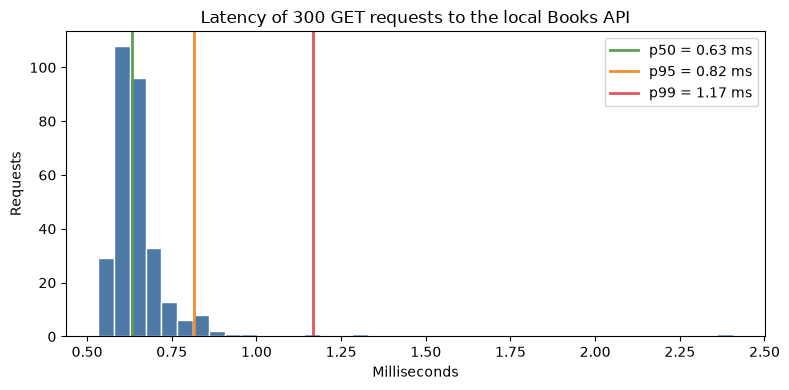

mean 0.65 ms | p50 0.63 | p95 0.82 | p99 1.17 | max 2.41


In [4]:
import statistics

import matplotlib.pyplot as plt

latencies = []
for i in range(300):
    t = time.perf_counter()
    with urllib.request.urlopen(f"{BASE}/v1/books/{i % 3 + 1}") as r:
        r.read()
    latencies.append((time.perf_counter() - t) * 1000)

q = statistics.quantiles(latencies, n=100)
p50, p95, p99 = q[49], q[94], q[98]
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(latencies, bins=40, color="#4E79A7", edgecolor="white")
for value, label, color in [(p50, "p50", "#59A14F"), (p95, "p95", "#F28E2B"), (p99, "p99", "#E15759")]:
    ax.axvline(value, color=color, lw=2, label=f"{label} = {value:.2f} ms")
ax.set(title="Latency of 300 GET requests to the local Books API", xlabel="Milliseconds", ylabel="Requests")
ax.legend()
plt.tight_layout()
plt.show()
print(f"mean {statistics.mean(latencies):.2f} ms | p50 {p50:.2f} | p95 {p95:.2f} | p99 {p99:.2f} | max {max(latencies):.2f}")
server.shutdown()

*Insight: Design the API contract first: resources, methods, status codes, error format and versioning. Make retried requests safe with idempotency, and judge performance by p95/p99 latency, not by the mean.*

## Real-World Use Case or Analogy

An API is like the **menu and the ordering rules of a restaurant**. The menu (OpenAPI document) lists what you can order and how; the waiter (HTTP) takes standard kinds of orders (methods); the kitchen answers with a dish or a clear explanation ("we are out of fish", a 404 with details). A good restaurant does not cook a second dish when you repeat your order because the waiter did not hear you (idempotency).

Payment providers such as Stripe made idempotency keys and consistent error objects an industry standard. LLM providers expose OpenAPI-described REST APIs, and the **Model Context Protocol** (MCP, M29) uses the same ideas to describe tools for AI agents.